# Food Delivery Data Analysis — Week 2: Exploratory Data Analysis

## 1. Objective

This notebook explores the cleaned food-delivery dataset to understand delivery-duration patterns and examine how delivery time varies across selected operational factors.

The analysis focuses on:

1. Establishing a baseline for delivery duration.
2. Comparing delivery duration across traffic, weather, vehicle type, and multiple-delivery categories.
3. Examining the relationship between estimated geographical distance and delivery duration.
4. Exploring the relationship between delivery-person ratings and delivery duration.
5. Recording evidence-based observations without making causal claims.

**Important:** This is exploratory analysis. Differences and correlations describe associations in this dataset; they do not prove that one factor causes a change in delivery duration.

## 2. Dataset and analysis decisions

- The cleaned dataset from Week 1 is used as the starting point. The raw dataset is not modified.
- `Time_taken (min)` is the delivery-duration variable, measured in minutes.
- Missing category values are excluded from category summaries by Pandas' default `groupby()` behavior. Their counts are checked separately where relevant.
- Week 1 data-quality decisions are retained. In particular, age values are not automatically removed, rating values of 6 are investigated through sensitivity analysis, and coordinate anomalies are handled transparently rather than silently corrected.
- The dataset does not contain a documented delivery-partner experience variable. `Delivery_person_ID` is an identifier, not a measure of experience.

## 3. Import libraries and locate the project

The project-root logic supports two common working locations:
- If the notebook is running from the `notebooks` folder, the project root is its parent.
- If it is running from the project root, the current directory is used.

This avoids relying on a personal, machine-specific Windows path.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Identify the project root without hard-coding a personal computer path.
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

# Build the path to the cleaned Week 1 dataset.
CLEAN_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "cleaned_food_delivery.csv"

# Check that the expected file exists before trying to load it.
if not CLEAN_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Cleaned dataset not found at: {CLEAN_DATA_PATH}\n"
        "Run this notebook from the project root or the notebooks folder."
    )

## 4. Load the cleaned dataset

A separate working copy is created so that the original cleaned data remains unchanged during analysis.

In [3]:
# Load the cleaned dataset produced in Week 1.
df_clean = pd.read_csv(CLEAN_DATA_PATH)

# Use a working copy for the Week 2 analysis.
df = df_clean.copy()

# Display the dataset dimensions and a small sample.
print(f"Number of records: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]:,}")

display(df.head())

Number of records: 45,584
Number of columns: 20


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,2022-02-12,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,2022-02-13,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,2022-03-04,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,2022-02-13,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,2022-02-14,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


## 5. Inspect data types and missing values

This inspection confirms the available variables and identifies missing values before calculating summaries. It also helps distinguish variables that can be analyzed from those that are unavailable or incomplete.

In [4]:
# Review column names, data types, and non-null counts.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  str    
 1   Delivery_person_ID           45584 non-null  str    
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  str    
 9   Time_Orderd                  43853 non-null  str    
 10  Time_Order_picked            45584 non-null  str    
 11  Weather_conditions           44968 non-null  str    
 12  Road_traffic_density         44983 non-null  str    
 13  Vehicle_condition          

In [5]:
# Summarize missing values by column.
missing_summary = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing percentage": (df.isna().mean() * 100).round(2)
})

# Show columns with the largest missing percentages first.
missing_summary = missing_summary.sort_values(
    by="Missing percentage",
    ascending=False
)

display(missing_summary)

,Missing count,Missing percentage
Delivery_person_Ratings,1908,4.19
Delivery_person_Age,1854,4.07
Time_Orderd,1731,3.80
City,1200,2.63
multiple_deliveries,993,2.18
Weather_conditions,616,1.35
Road_traffic_density,601,1.32
Festival,228,0.50
ID,0,0.00
Delivery_person_ID,0,0.00


## 6. Delivery-duration baseline

The target variable is `Time_taken (min)`. Its descriptive statistics establish the overall reference point against which the category and distance analyses can be compared.

The count is included to show how many non-missing delivery-duration observations contribute to the statistics.

In [6]:
DURATION_COL = "Time_taken (min)"

# Calculate the main descriptive statistics for delivery duration.
duration_baseline = df[DURATION_COL].describe(
    percentiles=[0.25, 0.50, 0.75]
).round(2)

display(duration_baseline)

count    45584.00
mean        26.29
std          9.38
min         10.00
25%         19.00
50%         26.00
75%         32.00
max         54.00
Name: Time_taken (min), dtype: float64

### Baseline interpretation

The dataset contains **45,584** delivery-duration observations. The mean duration is **26.29 minutes**, while the median is **26 minutes**. The middle 50% of deliveries fall between **19 and 32 minutes** (the 25th and 75th percentiles). Recorded durations range from **10 to 54 minutes**.

The mean is slightly higher than the median, which is consistent with a modest right tail: a smaller number of longer deliveries pull the average upward.

### 6.1 Distribution of delivery duration

The histogram shows how frequently each delivery duration occurs. The KDE curve provides a smoothed view of the distribution's overall shape.

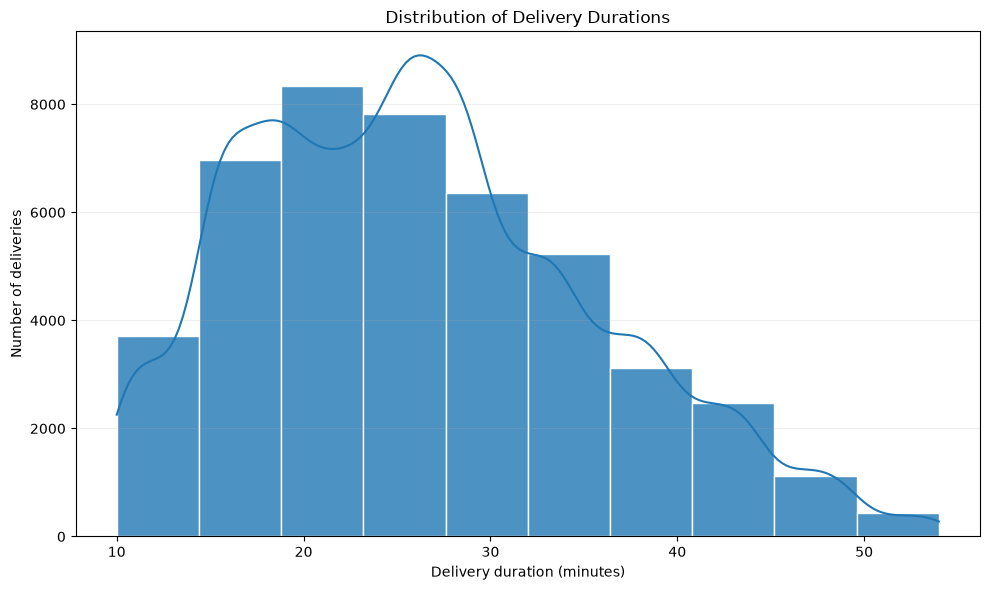

In [7]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x=DURATION_COL,
    bins=10,
    kde=True,
    edgecolor="white",
    alpha=0.8
)

plt.title("Distribution of Delivery Durations")
plt.xlabel("Delivery duration (minutes)")
plt.ylabel("Number of deliveries")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

**Interpretation:** Most delivery durations are concentrated around the central part of the distribution, with fewer observations at the longer-duration end. This is consistent with the mean being slightly greater than the median. The histogram describes the overall distribution; it does not identify why some deliveries take longer.

### 6.2 Potential outliers using the IQR rule

The interquartile range (IQR) is the difference between the 75th and 25th percentiles. The conventional 1.5 × IQR rule flags observations below the lower fence or above the upper fence as *potential* outliers.

These statistical flags do not automatically mean that the records are incorrect.

In [8]:
# Calculate the quartiles and interquartile range.
q1 = df[DURATION_COL].quantile(0.25)
q3 = df[DURATION_COL].quantile(0.75)
iqr = q3 - q1

# Calculate the conventional 1.5 × IQR lower and upper fences.
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# Identify observations outside the fences.
potential_outliers = df.loc[
    (df[DURATION_COL] < lower_fence) | (df[DURATION_COL] > upper_fence),
    DURATION_COL
]

print(f"Q1: {q1:.2f} minutes")
print(f"Q3: {q3:.2f} minutes")
print(f"IQR: {iqr:.2f} minutes")
print(f"Lower fence: {lower_fence:.2f} minutes")
print(f"Upper fence: {upper_fence:.2f} minutes")
print(f"Potential outliers: {len(potential_outliers):,}")
print(f"Percentage of records: {len(potential_outliers) / df[DURATION_COL].notna().sum() * 100:.2f}%")

# Show the frequencies of the flagged duration values.
display(potential_outliers.value_counts().sort_index())

Q1: 19.00 minutes
Q3: 32.00 minutes
IQR: 13.00 minutes
Lower fence: -0.50 minutes
Upper fence: 51.50 minutes
Potential outliers: 270
Percentage of records: 0.59%


Time_taken (min)
52     79
53    100
54     91
Name: count, dtype: int64

### Boxplot and outlier interpretation

The IQR rule gives a lower fence of **−0.5 minutes** and an upper fence of **51.5 minutes**. Since the observed minimum is 10 minutes, there are no lower-fence outliers. There are **270 potential upper outliers (0.59%)**, with durations from **52 to 54 minutes**.

These records are retained. Their values are possible long delivery durations, and the IQR rule alone is not evidence that they are data errors.

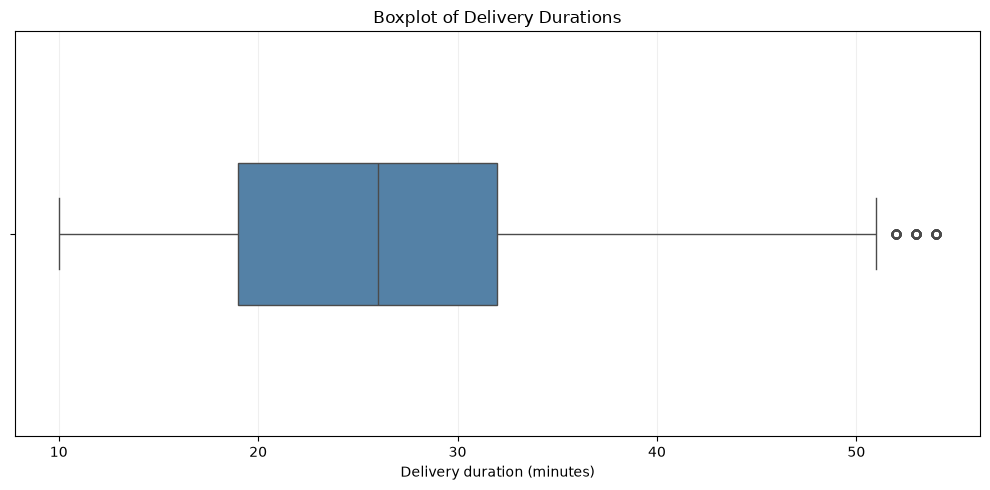

In [9]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x=DURATION_COL,
    color="steelblue",
    width=0.35
)

plt.title("Boxplot of Delivery Durations")
plt.xlabel("Delivery duration (minutes)")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 7. Compare delivery duration across operational categories

The following categorical variables are available:
- `Road_traffic_density`
- `Weather_conditions`
- `Type_of_vehicle`
- `multiple_deliveries`

For each category, the analysis reports:
- **count:** number of records in the category with a non-missing delivery duration;
- **mean:** average delivery duration in minutes;
- **median:** middle delivery duration in minutes.

A dictionary maps readable analysis labels to the corresponding dataset columns. A single loop applies the same aggregation consistently to each variable.

By default, `groupby()` excludes rows where the grouping variable is missing. The missing-value table above should therefore be considered when interpreting the group counts.

In [10]:
# Map each analysis label to its corresponding categorical column.
grouping_columns = {
    "Traffic": "Road_traffic_density",
    "Weather": "Weather_conditions",
    "Vehicle type": "Type_of_vehicle",
    "Multiple deliveries": "multiple_deliveries"
}

# Store one summary DataFrame for each categorical variable.
category_summaries = {}

for analysis_name, category_column in grouping_columns.items():
    category_summary = (
        df.groupby(category_column)[DURATION_COL]
        .agg(count="count", mean="mean", median="median")
        .round(2)
        .sort_values(by="mean", ascending=False)
    )

    category_summaries[analysis_name] = category_summary

# Display the four summaries without merging unlike category variables.
for analysis_name, summary in category_summaries.items():
    print(f"\n{analysis_name}")
    display(summary)


Traffic


,count,mean,median
Road_traffic_density,,,
Jam,14139,31.18,31.0
High,4423,27.24,27.0
Medium,10945,26.70,27.0
Low,15476,21.27,20.0



Weather


,count,mean,median
Weather_conditions,,,
Cloudy,7533,28.92,28.0
Fog,7653,28.91,28.0
Windy,7422,26.12,26.0
Sandstorms,7494,25.88,26.0
Stormy,7584,25.87,26.0
Sunny,7282,21.86,20.0



Vehicle type


,count,mean,median
Type_of_vehicle,,,
motorcycle,26429,27.61,26.0
bicycle,68,26.43,26.0
scooter,15273,24.48,24.0
electric_scooter,3814,24.47,24.0



Multiple deliveries


,count,mean,median
multiple_deliveries,,,
3.0,361,47.82,48.0
2.0,1985,40.45,40.0
1.0,28151,26.85,26.0
0.0,14094,22.88,22.0


### 7.1 Traffic density

**Evidence:** Jam traffic has the highest mean duration (**31.18 minutes**, n = **14,139**) and median (**31 minutes**). Low traffic has the lowest mean (**21.27 minutes**, n = **15,476**) and median (**20 minutes**). The median difference between these two categories is **11 minutes**. High and Medium traffic have relatively close mean durations (**27.24** and **26.70 minutes**).

**Interpretation:** Delivery duration is higher in the Jam category than in the Low category in this dataset. This is an association; distance, weather, time of day, and other operational factors may also contribute. The dataset's category `Jam` is treated as the highest traffic-density category based on the Week 1 mentor clarification.

### 7.2 Weather conditions

**Evidence:** Cloudy conditions have the highest mean duration (**28.92 minutes**, n = **7,533**), closely followed by Fog (**28.91 minutes**, n = **7,653**). Sunny conditions have the lowest mean (**21.86 minutes**, n = **7,282**). The corresponding medians are 28 minutes for Cloudy and Fog, and 20 minutes for Sunny.

**Interpretation:** Deliveries recorded under Cloudy and Fog conditions tend to have longer durations than those recorded under Sunny conditions in this dataset. This comparison does not establish that weather alone explains the difference.

### 7.3 Vehicle type

**Evidence:** Motorcycle deliveries have the highest mean duration (**27.61 minutes**, n = **26,429**) and median (**26 minutes**). Electric scooter deliveries have the lowest mean (**24.47 minutes**, n = **3,814**) and median (**24 minutes**). Scooter and electric-scooter mean durations are almost identical. Bicycle has only **68** records.

**Interpretation:** The observed average duration differs across vehicle categories, but the differences are modest for scooter and electric scooter. The bicycle group is much smaller than the other groups, so its summary should be interpreted cautiously. The dataset does not provide enough documentation to infer vehicle-condition codes or other unrecorded vehicle characteristics.

### 7.4 Multiple deliveries

**Evidence:** Median duration increases across the recorded `multiple_deliveries` values: **22 minutes** for category 0 (n = **14,094**), **26 minutes** for category 1 (n = **28,151**), **40 minutes** for category 2 (n = **1,985**), and **48 minutes** for category 3 (n = **361**). Mean durations are 22.88, 26.85, 40.45, and 47.82 minutes, respectively.

**Interpretation:** Higher values in `multiple_deliveries` are associated with longer delivery durations in this dataset. Categories 2 and 3 have substantially fewer records, especially category 3, so their estimates are less stable. The analysis describes the recorded category values and does not assume an undocumented operational definition for category 0.

## 8. Distance and delivery duration

The dataset does not contain a ready-made distance variable. A straight-line distance is estimated from restaurant and delivery coordinates using the Haversine formula.

### 8.1 Coordinate quality checks

Week 1 identified unusual coordinate patterns. In particular, **3,640** records have both delivery coordinates between 0 and 1 inclusive, and the two coordinate values are equal in all 3,640 records. These pairs are treated as suspicious for this distance analysis. This is an explicit analysis rule based on the observed pattern, not proof of the actual intended locations.

Restaurant coordinates also include zero and negative values. Because the dataset has no accompanying coordinate documentation, the negative values cannot be confidently corrected. Two scenarios are therefore compared rather than presenting one interpretation as certain:

- **Scenario A — strict:** retain records only when both restaurant coordinates are greater than zero, and exclude the suspicious delivery-coordinate pairs.
- **Scenario B — absolute-value sensitivity scenario:** exclude records where either restaurant coordinate is zero, exclude the same suspicious delivery-coordinate pairs, then take the absolute values of negative restaurant coordinates.

**Important limitation:** Taking absolute values is a hypothetical sensitivity test, not a validated geographic correction. Latitude and longitude signs identify hemispheres; changing signs can move a point to a different location. Scenario B is included only to show how this assumption affects the distance analysis. Scenario A is the more conservative primary scenario.

In [11]:
# Select the four coordinate columns for a compact quality summary.
coordinate_columns = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]

# Summarize missing, zero, negative, minimum, and maximum values.
coordinate_summary = pd.DataFrame({
    "Missing": df[coordinate_columns].isna().sum(),
    "Zero": (df[coordinate_columns] == 0).sum(),
    "Negative": (df[coordinate_columns] < 0).sum(),
    "Minimum": df[coordinate_columns].min(),
    "Maximum": df[coordinate_columns].max()
})

display(coordinate_summary.round(4))

,Missing,Zero,Negative,Minimum,Maximum
Restaurant_latitude,0,3640,431,-30.9056,30.9141
Restaurant_longitude,0,3640,162,-88.3662,88.4335
Delivery_location_latitude,0,0,0,0.0100,31.0541
Delivery_location_longitude,0,0,0,0.0100,88.5635


In [12]:
# Flag records where BOTH delivery coordinates fall between 0 and 1 inclusive.
# These are excluded from both distance scenarios due to the unusual paired pattern.
suspicious_delivery_mask = (
    df["Delivery_location_latitude"].between(0, 1)
    & df["Delivery_location_longitude"].between(0, 1)
)

# Count how many records meet this condition.
print(f"Records with both delivery coordinates in [0, 1]: {suspicious_delivery_mask.sum():,}")

# Check whether latitude and longitude are equal in all flagged records.
equal_coordinate_count = (
    df.loc[suspicious_delivery_mask, "Delivery_location_latitude"]
    == df.loc[suspicious_delivery_mask, "Delivery_location_longitude"]
).sum()

print(f"Flagged records with equal delivery latitude and longitude: {equal_coordinate_count:,}")

Records with both delivery coordinates in [0, 1]: 3,640
Flagged records with equal delivery latitude and longitude: 3,640


### 8.2 Define the two coordinate scenarios

The delivery-coordinate exclusion is shared by both scenarios. Only the restaurant-coordinate rule differs.

The masks are combined using `&`, which means a record must satisfy both the delivery-coordinate condition and the restaurant-coordinate condition to be retained.

In [13]:
# Shared rule: exclude the suspicious delivery-coordinate pairs in both scenarios.
delivery_coordinates_present = df[
    ["Delivery_location_latitude", "Delivery_location_longitude"]
].notna().all(axis=1)
delivery_valid = delivery_coordinates_present & ~suspicious_delivery_mask

# Scenario A: both restaurant coordinates must be strictly positive.
restaurant_valid_A = (
    df[["Restaurant_latitude", "Restaurant_longitude"]].notna().all(axis=1)
    & (df["Restaurant_latitude"] > 0)
    & (df["Restaurant_longitude"] > 0)
)

# Scenario B: neither restaurant coordinate may equal zero.
# Negative values are retained for the later absolute-value sensitivity test.
restaurant_valid_B = (
    df[["Restaurant_latitude", "Restaurant_longitude"]].notna().all(axis=1)
    & (df["Restaurant_latitude"] != 0)
    & (df["Restaurant_longitude"] != 0)
)

# Combine the shared delivery rule with each scenario's restaurant rule.
scenario_A_mask = delivery_valid & restaurant_valid_A
scenario_B_mask = delivery_valid & restaurant_valid_B

print(f"Records retained in Scenario A: {scenario_A_mask.sum():,}")
print(f"Records retained in Scenario B: {scenario_B_mask.sum():,}")

Records retained in Scenario A: 41,513
Records retained in Scenario B: 41,944


In [14]:
# Create independent copies so coordinate transformations cannot affect df.
df_A = df.loc[scenario_A_mask].copy()
df_B = df.loc[scenario_B_mask].copy()

# Apply absolute values to restaurant coordinates in Scenario B only.
df_B[["Restaurant_latitude", "Restaurant_longitude"]] = (
    df_B[["Restaurant_latitude", "Restaurant_longitude"]].abs()
)

# Confirm that Scenario B's transformed restaurant coordinates are positive.
display(df_B[["Restaurant_latitude", "Restaurant_longitude"]].min())

Restaurant_latitude      9.957144
Restaurant_longitude    72.768726
dtype: float64

### 8.3 Haversine distance function

The Haversine formula estimates the great-circle distance between two points on a sphere using their latitudes and longitudes.

Steps:
1. Convert all four coordinates from degrees to radians because NumPy's trigonometric functions use radians.
2. Calculate the differences in latitude and longitude.
3. Apply the Haversine formula to calculate the central angle between the two points.
4. Multiply the angle by the Earth's mean radius (approximately 6,371 km) to obtain distance in kilometres.

The function accepts scalar coordinates for one record at a time.

In [15]:
def haversine_distance(lat1, lon1, lat2, lon2):
    # Mean radius of the Earth in kilometres.
    earth_radius_km = 6371

    # Convert coordinate values from degrees to radians.
    lat1, lon1, lat2, lon2 = np.radians((lat1, lon1, lat2, lon2))

    # Calculate the differences between the two locations.
    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1

    # Apply the Haversine formula to obtain the squared half-chord length.
    a = (
        np.sin(delta_lat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2) ** 2
    )

    # Convert the central angle into a distance in kilometres.
    # Clip tiny floating-point deviations to the valid [0, 1] range.
    a = np.clip(a, 0, 1)

    central_angle = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

    return earth_radius_km * central_angle

In [16]:
# Simple sanity check: one degree of longitude at the equator is about 111 km.
haversine_distance(0, 0, 0, 1)

np.float64(111.19492664455873)

### 8.4 Calculate distance in both scenarios

The same calculation is applied to Scenario A and Scenario B using a loop. `DataFrame.apply(axis=1)` passes one row at a time to the function; the `lambda` expression supplies that row's four coordinate values.

This avoids writing the same distance-calculation block twice.

In [17]:
# Keep the two scenario DataFrames together so the same operation can be reused.
distance_scenarios = {
    "A": df_A,
    "B": df_B
}

for scenario_name, scenario_df in distance_scenarios.items():
    # Calculate restaurant-to-delivery straight-line distance for every row.
    scenario_df["Distance_km"] = scenario_df.apply(
        lambda row: haversine_distance(
            row["Restaurant_latitude"],
            row["Restaurant_longitude"],
            row["Delivery_location_latitude"],
            row["Delivery_location_longitude"]
        ),
        axis=1
    )

In [18]:
# Check the calculated distance values in each scenario.
distance_checks = {}

for scenario_name, scenario_df in distance_scenarios.items():
    distance_checks[scenario_name] = {
        "Records": len(scenario_df),
        "Missing distances": int(scenario_df["Distance_km"].isna().sum()),
        "Minimum distance (km)": round(scenario_df["Distance_km"].min(), 2),
        "Maximum distance (km)": round(scenario_df["Distance_km"].max(), 2)
    }

display(pd.DataFrame(distance_checks).T)

,Records,Missing distances,Minimum distance (km),Maximum distance (km)
A,41513.0,0.0,1.47,20.97
B,41944.0,0.0,1.47,20.97


### 8.5 Correlation between distance and delivery duration

Pearson's correlation coefficient measures the strength and direction of a linear relationship between two numerical variables. It ranges from −1 to +1:

- A value near +1 indicates a strong positive linear association.
- A value near −1 indicates a strong negative linear association.
- A value near 0 indicates little linear association.

Correlation does not establish causation and may be influenced by the coordinate assumptions used to calculate distance.

In [19]:
# Calculate Pearson correlation for each coordinate scenario.
distance_correlations = {}

for scenario_name, scenario_df in distance_scenarios.items():
    distance_correlations[scenario_name] = scenario_df["Distance_km"].corr(
        scenario_df[DURATION_COL]
    )

display(pd.Series(distance_correlations, name="Pearson correlation"))

A    0.321062
B    0.320474
Name: Pearson correlation, dtype: float64

**Result and interpretation:** Scenario A produces a correlation of approximately **0.321**, while Scenario B produces approximately **0.320**. Both indicate a weak-to-moderate positive linear association between estimated straight-line distance and delivery duration in the analyzed records. The values are very similar across the two coordinate scenarios.

This similarity suggests that the correlation is not highly sensitive to these two particular coordinate-handling rules. However, it does not validate the absolute-value assumption in Scenario B or establish that the calculated distances represent actual road travel distances. The Haversine measure is straight-line distance, not route distance.

### 8.6 Initial scatter plot

Scenario A is used for the initial scatter plot because it applies the more conservative coordinate rule and does not alter coordinate signs. Each point represents one delivery record. Distance is placed on the x-axis and delivery duration on the y-axis.

The points overlap heavily because delivery duration takes a limited set of integer values and many records share similar distances. Smaller, partially transparent markers make overlapping observations easier to see.

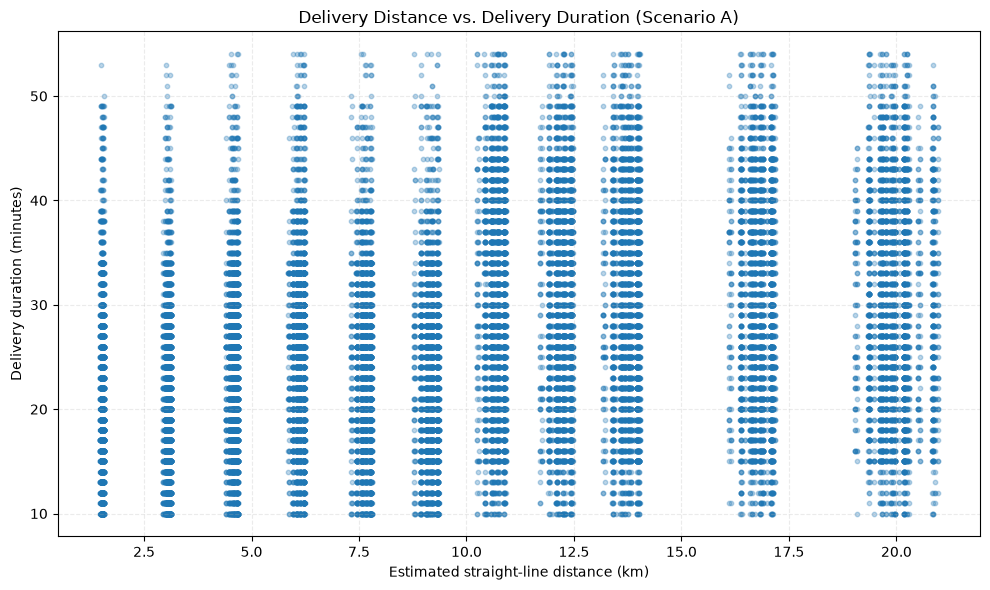

Plot saved to: C:\Users\DELL\food-delivery-data-analysis\visualizations\initial_distance_vs_duration.png


In [20]:
# Create the visualization folder if it does not already exist.
VISUALIZATION_DIR = PROJECT_ROOT / "visualizations"
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 6))

plt.scatter(
    x=df_A["Distance_km"],
    y=df_A[DURATION_COL],
    s=10,
    alpha=0.3
)

plt.title("Delivery Distance vs. Delivery Duration (Scenario A)")
plt.xlabel("Estimated straight-line distance (km)")
plt.ylabel("Delivery duration (minutes)")
plt.grid(alpha=0.25, linestyle="--")
plt.tight_layout()

# Save the initial exploratory plot in the required project location.
plot_path = VISUALIZATION_DIR / "initial_distance_vs_duration.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Plot saved to: {plot_path}")

## 9. Delivery-person ratings and delivery duration

The rating column contains many distinct decimal values. To make the comparison easier to interpret, valid ratings are grouped into three bands:

- **Lower:** rating < 4.0
- **Middle:** 4.0 ≤ rating < 4.5
- **High:** 4.5 ≤ rating ≤ 5.0

Week 1 mentor feedback identified 1–5 as the expected rating scale and 53 records with a rating of 6. These 53 records are not silently deleted from the working dataset. They are outside the three valid rating bands and are assessed separately through a sensitivity comparison.

A separate analysis copy is used so the main `df` remains unchanged.

In [21]:
# Work on a separate copy for rating analysis.
rating_df = df.copy()

# Divide valid ratings into three interpretable intervals.
rating_df["Rating_group"] = pd.cut(
    rating_df["Delivery_person_Ratings"],
    bins=[0, 4, 4.5, 5.1],
    labels=["Lower", "Middle", "High"],
    right=False
)

# Count each rating group, including values not assigned to a valid group.
rating_group_counts = rating_df["Rating_group"].value_counts(dropna=False).sort_index()
display(rating_group_counts)

Rating_group
Lower      1367
Middle     6694
High      35562
NaN        1961
Name: count, dtype: int64

The three valid rating groups contain **1,367 Lower**, **6,694 Middle**, and **35,562 High** records. The `NaN` group contains **1,961** records: **1,908 missing ratings** and **53 ratings of 6**. These two reasons for a missing group assignment are kept distinct in the interpretation.

In [22]:
# Compare delivery-duration statistics across the three valid rating groups.
rating_summary = (
    rating_df.dropna(subset=["Rating_group"])
    .groupby("Rating_group", observed=True)[DURATION_COL]
    .agg(count="count", mean="mean", median="median")
    .round(2)
    .sort_values(by="mean", ascending=False)
)

display(rating_summary)

,count,mean,median
Rating_group,,,
Lower,1367,36.83,36.0
Middle,6694,34.65,34.0
High,35562,24.31,24.0


### Rating-group interpretation

**Evidence:** The Lower rating group has a mean delivery duration of **36.83 minutes** and median of **36 minutes** (n = **1,367**). The Middle group has a mean of **34.65 minutes** and median of **34 minutes** (n = **6,694**). The High group has a mean of **24.31 minutes** and median of **24 minutes** (n = **35,562**). The median difference between the Lower and High groups is **12 minutes**.

**Interpretation:** Higher delivery-person rating groups are associated with shorter delivery durations in this dataset. This pattern does not establish whether delivery duration influences ratings, ratings influence delivery duration, or other factors influence both. The group sizes are also substantially different.

### 9.1 Sensitivity analysis for rating value 6

To assess whether the 53 records with rating 6 materially affect the overall delivery-duration baseline, compare the full dataset with a version excluding only those 53 records.

Records with missing ratings are retained in both datasets. This comparison concerns the overall delivery-duration statistics, not the rating-group averages.

In [23]:
# Define the two versions used for the sensitivity comparison.
rating_scenarios = {
    "Original dataset": df,
    "Excluding rating 6": df.loc[df["Delivery_person_Ratings"] != 6]
}

rating_sensitivity = {}

for scenario_name, scenario_df in rating_scenarios.items():
    # Summarize delivery duration, not the rating values themselves.
    rating_sensitivity[scenario_name] = (
        scenario_df[DURATION_COL]
        .agg(["count", "mean", "median"])
        .round(2)
    )

display(pd.DataFrame(rating_sensitivity).T)

,count,mean,median
Original dataset,45584.0,26.29,26.0
Excluding rating 6,45531.0,26.30,26.0


**Sensitivity result:** The original dataset has **45,584** delivery-duration observations, a mean of **26.29 minutes**, and a median of **26 minutes**. Excluding the 53 records with rating 6 leaves **45,531** observations; the mean becomes **26.30 minutes**, while the median remains **26 minutes**.

The mean changes by only **0.01 minute**, and the median does not change. Therefore, these 53 records have a negligible effect on the overall delivery-duration baseline. They are retained in the main dataset, while the sensitivity result is documented as requested by the mentor.

## 10. Partner experience: data availability

The dataset does not include a documented delivery-partner experience or tenure variable. `Delivery_person_ID` identifies a delivery person but does not indicate how long that person has worked. Therefore, partner experience cannot be analyzed reliably from the available columns and is not inferred from the identifier.

## 11. Key evidence-based observations

The following observations summarize the main results. They describe patterns in this dataset and should not be interpreted as causal effects.

1. **Traffic density:** Jam traffic has the highest mean duration (**31.18 minutes**, n = **14,139**) and median (**31 minutes**), while Low traffic has the lowest mean (**21.27 minutes**, n = **15,476**) and median (**20 minutes**). The median difference is **11 minutes**.
2. **Weather:** Cloudy conditions have the highest mean duration (**28.92 minutes**, n = **7,533**), closely followed by Fog (**28.91 minutes**, n = **7,653**). Sunny conditions have the lowest mean (**21.86 minutes**, n = **7,282**).
3. **Vehicle type:** Motorcycle deliveries have the highest mean duration (**27.61 minutes**, n = **26,429**). Electric scooter deliveries have the lowest (**24.47 minutes**, n = **3,814**). Bicycle has only **68** records, so that category requires caution.
4. **Multiple deliveries:** Median duration rises from **22 minutes** in category 0 (n = **14,094**) to **48 minutes** in category 3 (n = **361**). Category 2 has a median of **40 minutes** (n = **1,985**), compared with **26 minutes** in category 1 (n = **28,151**).
5. **Delivery-person ratings:** Median duration is **36 minutes** in the Lower rating group (n = **1,367**), **34 minutes** in the Middle group (n = **6,694**), and **24 minutes** in the High group (n = **35,562**). The Lower-to-High median difference is **12 minutes**.
6. **Distance:** Estimated straight-line distance has a Pearson correlation of approximately **0.321** with delivery duration in Scenario A and **0.320** in Scenario B, indicating a positive linear association of modest strength.

### Limitations to keep in mind

- These are observational comparisons; they do not establish causation.
- Group sizes differ, and small categories (especially Bicycle and multiple-deliveries category 3) should be interpreted cautiously.
- Missing category values are not included in their respective `groupby()` summaries.
- The distance calculation depends on coordinate-quality assumptions. Scenario B is hypothetical, and straight-line distance is not the same as road distance.
- The dataset does not provide a data dictionary for every encoded field or a delivery-partner experience variable.
- Rating value 6 is outside the expected scale identified by the mentor; the sensitivity analysis shows that excluding those 53 records barely changes the overall duration baseline.

## 12. Conclusion

The exploratory analysis establishes a baseline delivery duration and identifies several operational categories associated with differences in delivery time. Traffic density and multiple-delivery category show notable differences in median duration. Weather, vehicle type, and delivery-person rating groups also show observable differences. Estimated straight-line distance has a positive but not strong linear association with delivery duration.

These findings provide a basis for the more focused visualizations and recommendations in the next project stage. They should be treated as exploratory evidence rather than causal conclusions.